In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [12]:

# Load dataset
iris = load_iris()

# Use two features for visualization
X = iris.data[:, :2]
y = (iris.target == 0).astype(int)  # Setosa = 1, Non-Setosa = 0

print("Feature names:", iris.feature_names[:2])
print("Target classes: 0 = Setosa, 1 = Non-Setosa")
print("Dataset shape:", X.shape)

print("\nFirst five rows:")
print(X[:5])



Feature names: ['sepal length (cm)', 'sepal width (cm)']
Target classes: 0 = Setosa, 1 = Non-Setosa
Dataset shape: (150, 2)

First five rows:
[[5.1 3.5]
 [4.9 3. ]
 [4.7 3.2]
 [4.6 3.1]
 [5.  3.6]]


In [13]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Training samples: 120
Testing samples: 30


In [14]:
# Create Linear SVM model
model = SVC(kernel='linear', C=1)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)



In [15]:
# Evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-Score:", f1_score(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Non-Setosa", "Setosa"]
))

Accuracy: 0.9666666666666667
Precision: 1.0
Recall: 0.9
F1-Score: 0.9473684210526316

Confusion Matrix:
[[20  0]
 [ 1  9]]

Classification Report:
              precision    recall  f1-score   support

  Non-Setosa       0.95      1.00      0.98        20
      Setosa       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.98      0.95      0.96        30
weighted avg       0.97      0.97      0.97        30



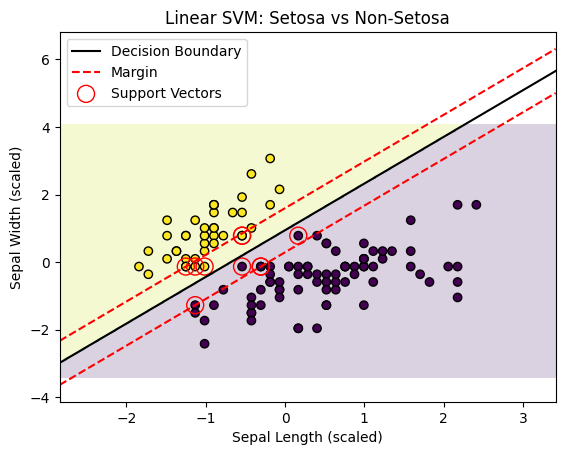

In [16]:
# Create a mesh grid
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Predict for each grid point
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision regions
plt.contourf(xx, yy, Z, alpha=0.2)

# Plot data points
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolors='black')

# Plot decision boundary and margins
w = model.coef_[0]
b = model.intercept_[0]

x_line = np.linspace(x_min, x_max, 200)
y_line = -(w[0] * x_line + b) / w[1]

plt.plot(x_line, y_line, 'k-', label='Decision Boundary')
plt.plot(x_line, y_line + 1 / w[1], 'r--', label='Margin')
plt.plot(x_line, y_line - 1 / w[1], 'r--')

# Highlight support vectors
plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=150, facecolors='none', edgecolors='red',
    label='Support Vectors'
)

plt.xlabel('Sepal Length (scaled)')
plt.ylabel('Sepal Width (scaled)')
plt.title('Linear SVM: Setosa vs Non-Setosa')
plt.legend()
plt.show()

In [18]:
print("\n Margin Width:")
w = model.coef_[0]
margin = 2 / np.linalg.norm(w)
print("   Margin width =", margin)

print("\n Impact of Margin:")
print("   A larger margin generally improves generalization.")
print("   A smaller margin may increase sensitivity to data.")
print("   SVM tries to maximize the margin while minimizing")
print("   classification errors, depending on parameter C.")


 Margin Width:
   Margin width = 0.7654793870695655

 Impact of Margin:
   A larger margin generally improves generalization.
   A smaller margin may increase sensitivity to data.
   SVM tries to maximize the margin while minimizing
   classification errors, depending on parameter C.
